<a href="https://colab.research.google.com/github/xufana/dl-knad-course/blob/main/week5/seminar_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Семинар: Сверточные архитектуры. Введение в задачу классификации


In [ ]:
import time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import models, transforms, datasets
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('torch', torch.__version__, '| device:', device)

torch 2.11.0+cu130 | device: cuda


## Часть 1. Задачи на кодинг нейронок

### 1.1 Реализация resudial block

Блок получает вектор `x` и возвращает `y = ReLU(F(x) + x)`, где `F(x) = W2 · ReLU(W1 · x)`.

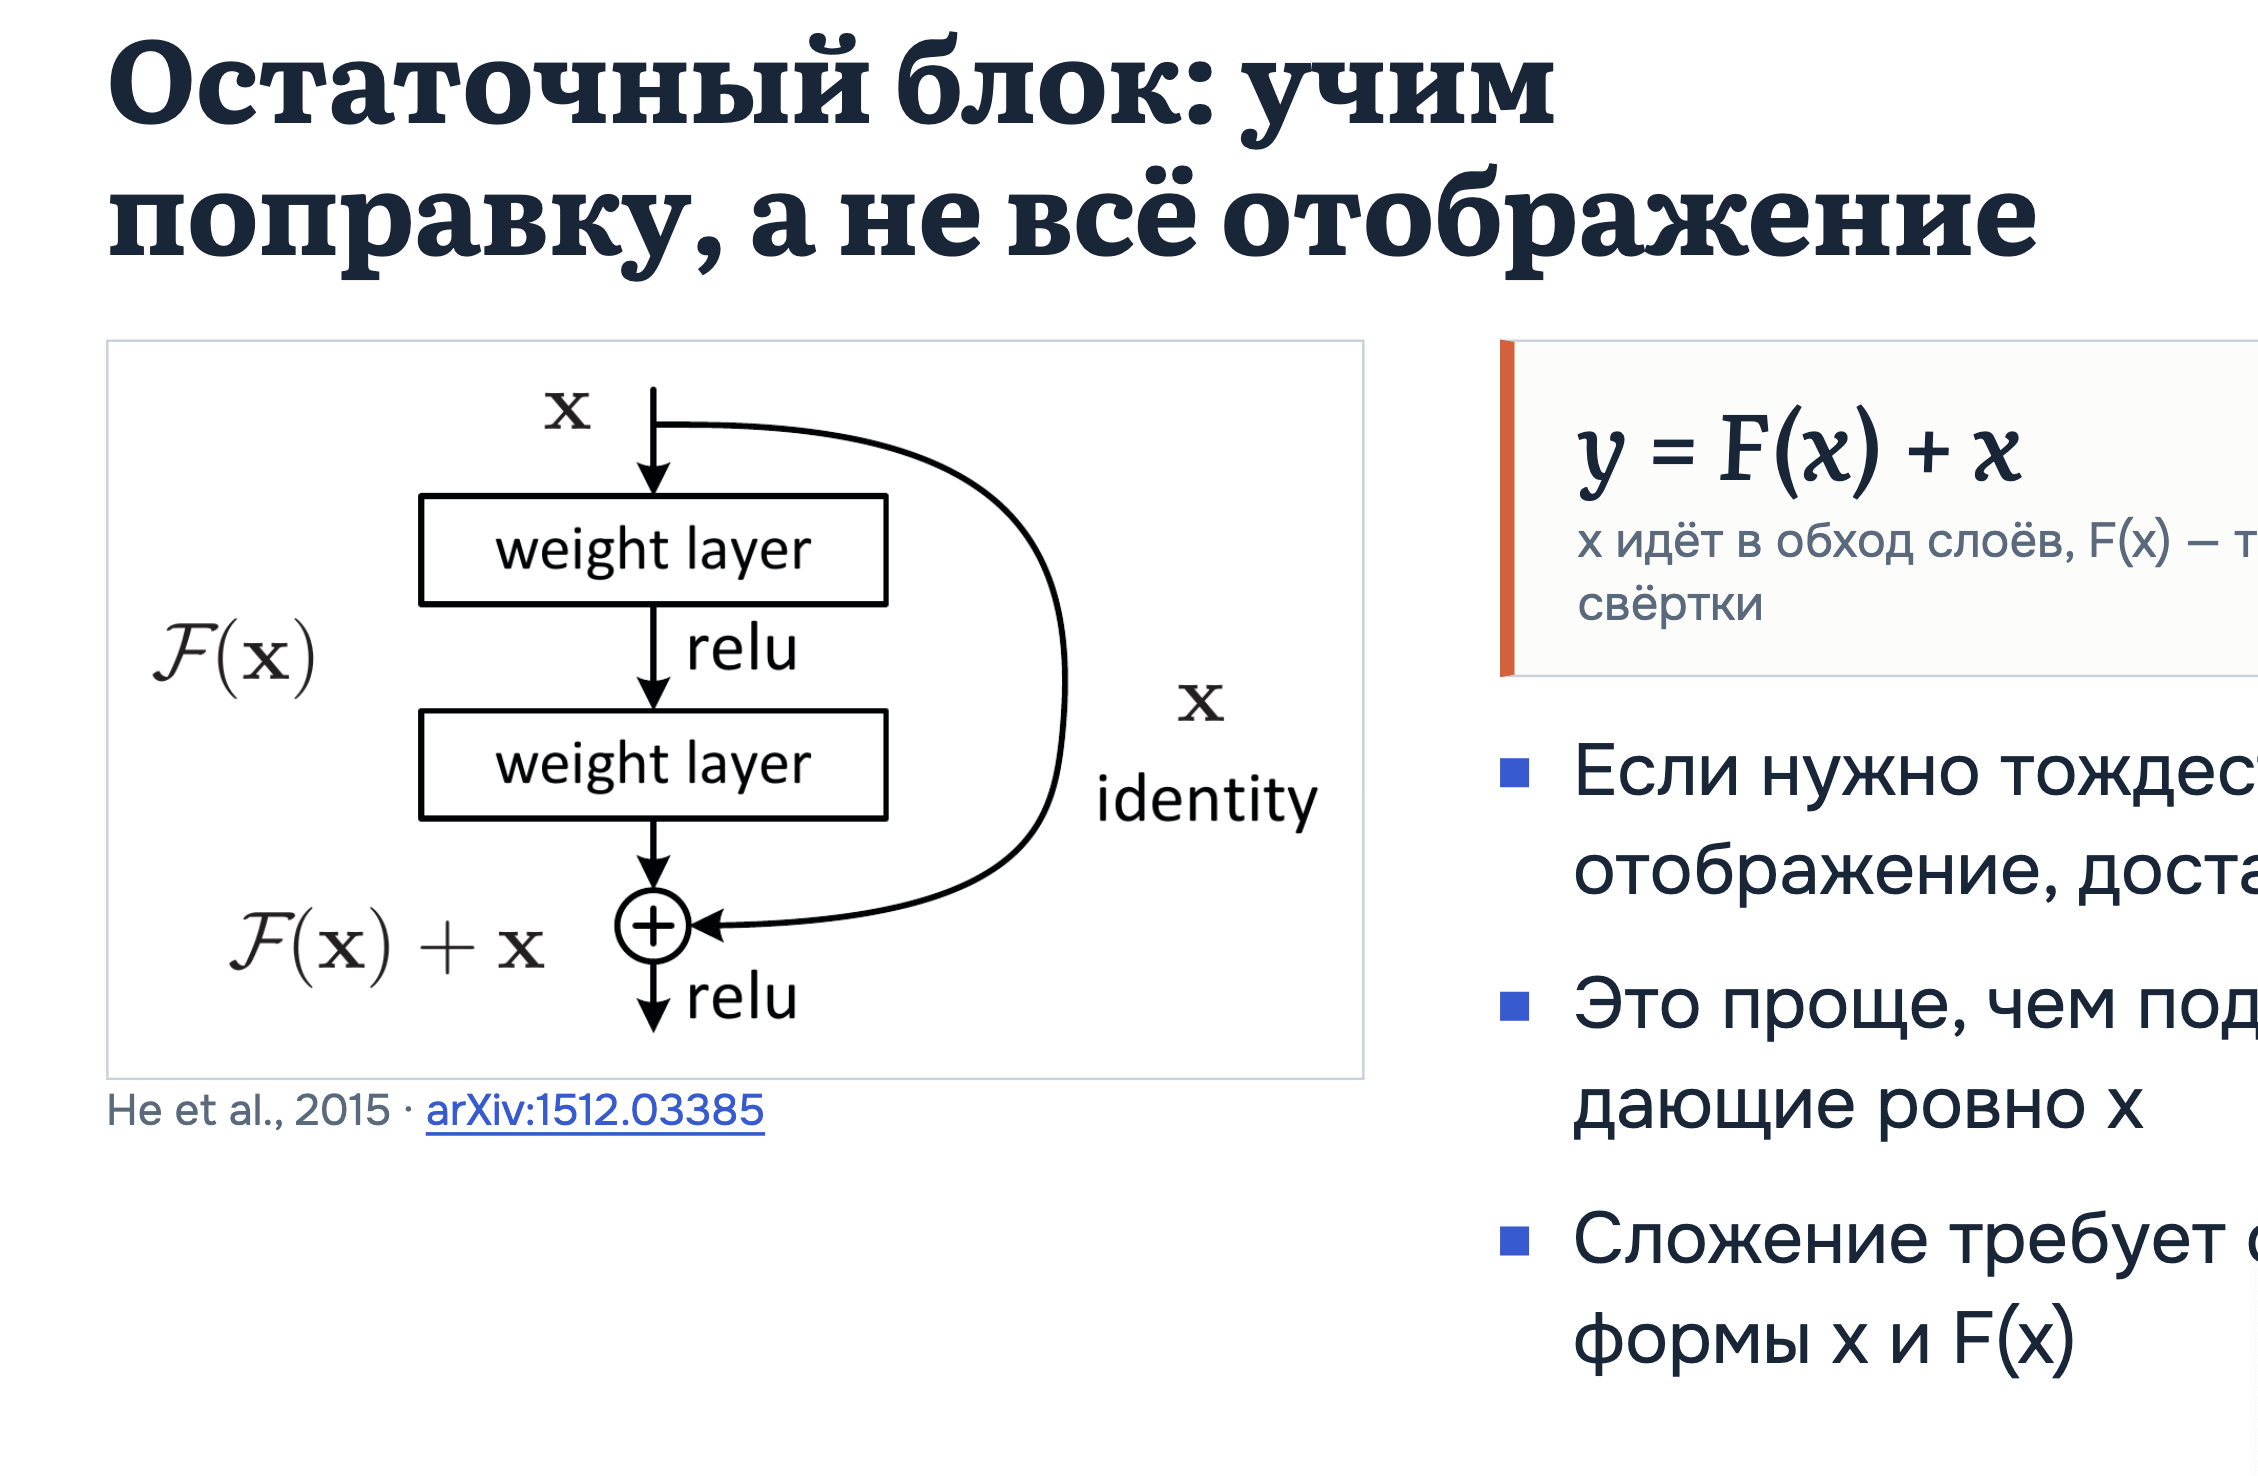

In [ ]:
def relu(x):
    return np.maximum(0, x)

In [ ]:
def residual_block(x, W1, W2):
    """x: (d,), W1: (h, d), W2: (d, h) -> (d,)"""
    return relu(W2 @ relu(W1 @ x)+ x)

In [ ]:
rng = np.random.default_rng(0)
d, h = 6, 4
x, W1, W2 = rng.normal(size=d), rng.normal(size=(h, d)), rng.normal(size=(d, h))

tx, t1, t2 = map(torch.from_numpy, (x, W1, W2))
ref = F.relu(t2 @ F.relu(t1 @ tx) + tx).numpy()
assert np.allclose(residual_block(x, W1, W2), ref), 'не совпало с PyTorch'
# если F(x) = 0, блок пропускает вход (с точностью до ReLU)
assert np.allclose(residual_block(x, 0 * W1, 0 * W2), relu(x)), 'при нулевых весах должно получиться relu(x)'
print('residual_block ✓')

residual_block ✓


**Эксперимент (запустите как есть).** Сложим 50 блоков с маленькими случайными весами: в одном случае с skip-соединением, в другом без. Следим за нормой сигнала.

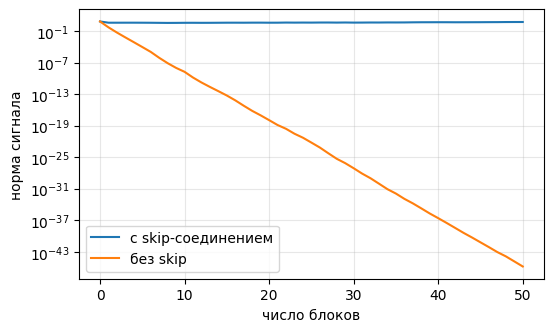

In [ ]:
def forward_stack(x, n_blocks, skip, scale=0.5, seed=1):
    rng = np.random.default_rng(seed)
    d, h = x.shape[0], x.shape[0]
    norms = [np.linalg.norm(x)]
    for _ in range(n_blocks):
        W1 = rng.normal(size=(h, d)) * scale / np.sqrt(d)
        W2 = rng.normal(size=(d, h)) * scale / np.sqrt(h)
        f = W2 @ relu(W1 @ x)
        x = relu(f + x) if skip else relu(f)
        norms.append(np.linalg.norm(x))
    return norms

x0 = np.random.default_rng(5).normal(size=64)
plt.figure(figsize=(6, 3.5))
plt.semilogy(forward_stack(x0, 50, skip=True),  label='с skip-соединением')
plt.semilogy(forward_stack(x0, 50, skip=False), label='без skip')
plt.xlabel('число блоков'); plt.ylabel('норма сигнала'); plt.legend(); plt.grid(alpha=.3); plt.show()

### 1.2 Global average pooling

Вход: тензор `(B, C, H, W)`. Выход: `(B, C)`, среднее по каждой карте.

In [ ]:
def global_avg_pool(x):
    """x: (B, C, H, W) -> (B, C)"""
    return x.mean(axis=(2,3))

In [ ]:
for hw in [(7, 7), (10, 15)]:          # разные размеры входа
    x = np.random.default_rng(0).normal(size=(2, 512, *hw))
    ref = F.adaptive_avg_pool2d(torch.from_numpy(x), 1).flatten(1).numpy()
    out = global_avg_pool(x)
    assert out.shape == (2, 512) and np.allclose(out, ref), f'ошибка для размера {hw}'
print('global_avg_pool ✓ (выход не зависит от H и W)')

# сколько параметров в первом FC после flatten и после GAP (K = 1000 классов)?
print('после GAP    :', 512 * 1000)
print('после flatten:', 512 * 7 * 7 * 1000)

global_avg_pool ✓ (выход не зависит от H и W)
после GAP    : 512000
после flatten: 25088000


### 1.3 BatchNorm для `(B, C, H, W)`

Для каждого канала `c` считаем среднее и дисперсию **по всем элементам канала: по батчу и по пространству** (`B·H·W` чисел). Затем `y = γ_c · (x − μ_c)/√(σ_c² + ε) + β_c`. Дисперсия смещённая (делим на N, как в PyTorch в режиме обучения).

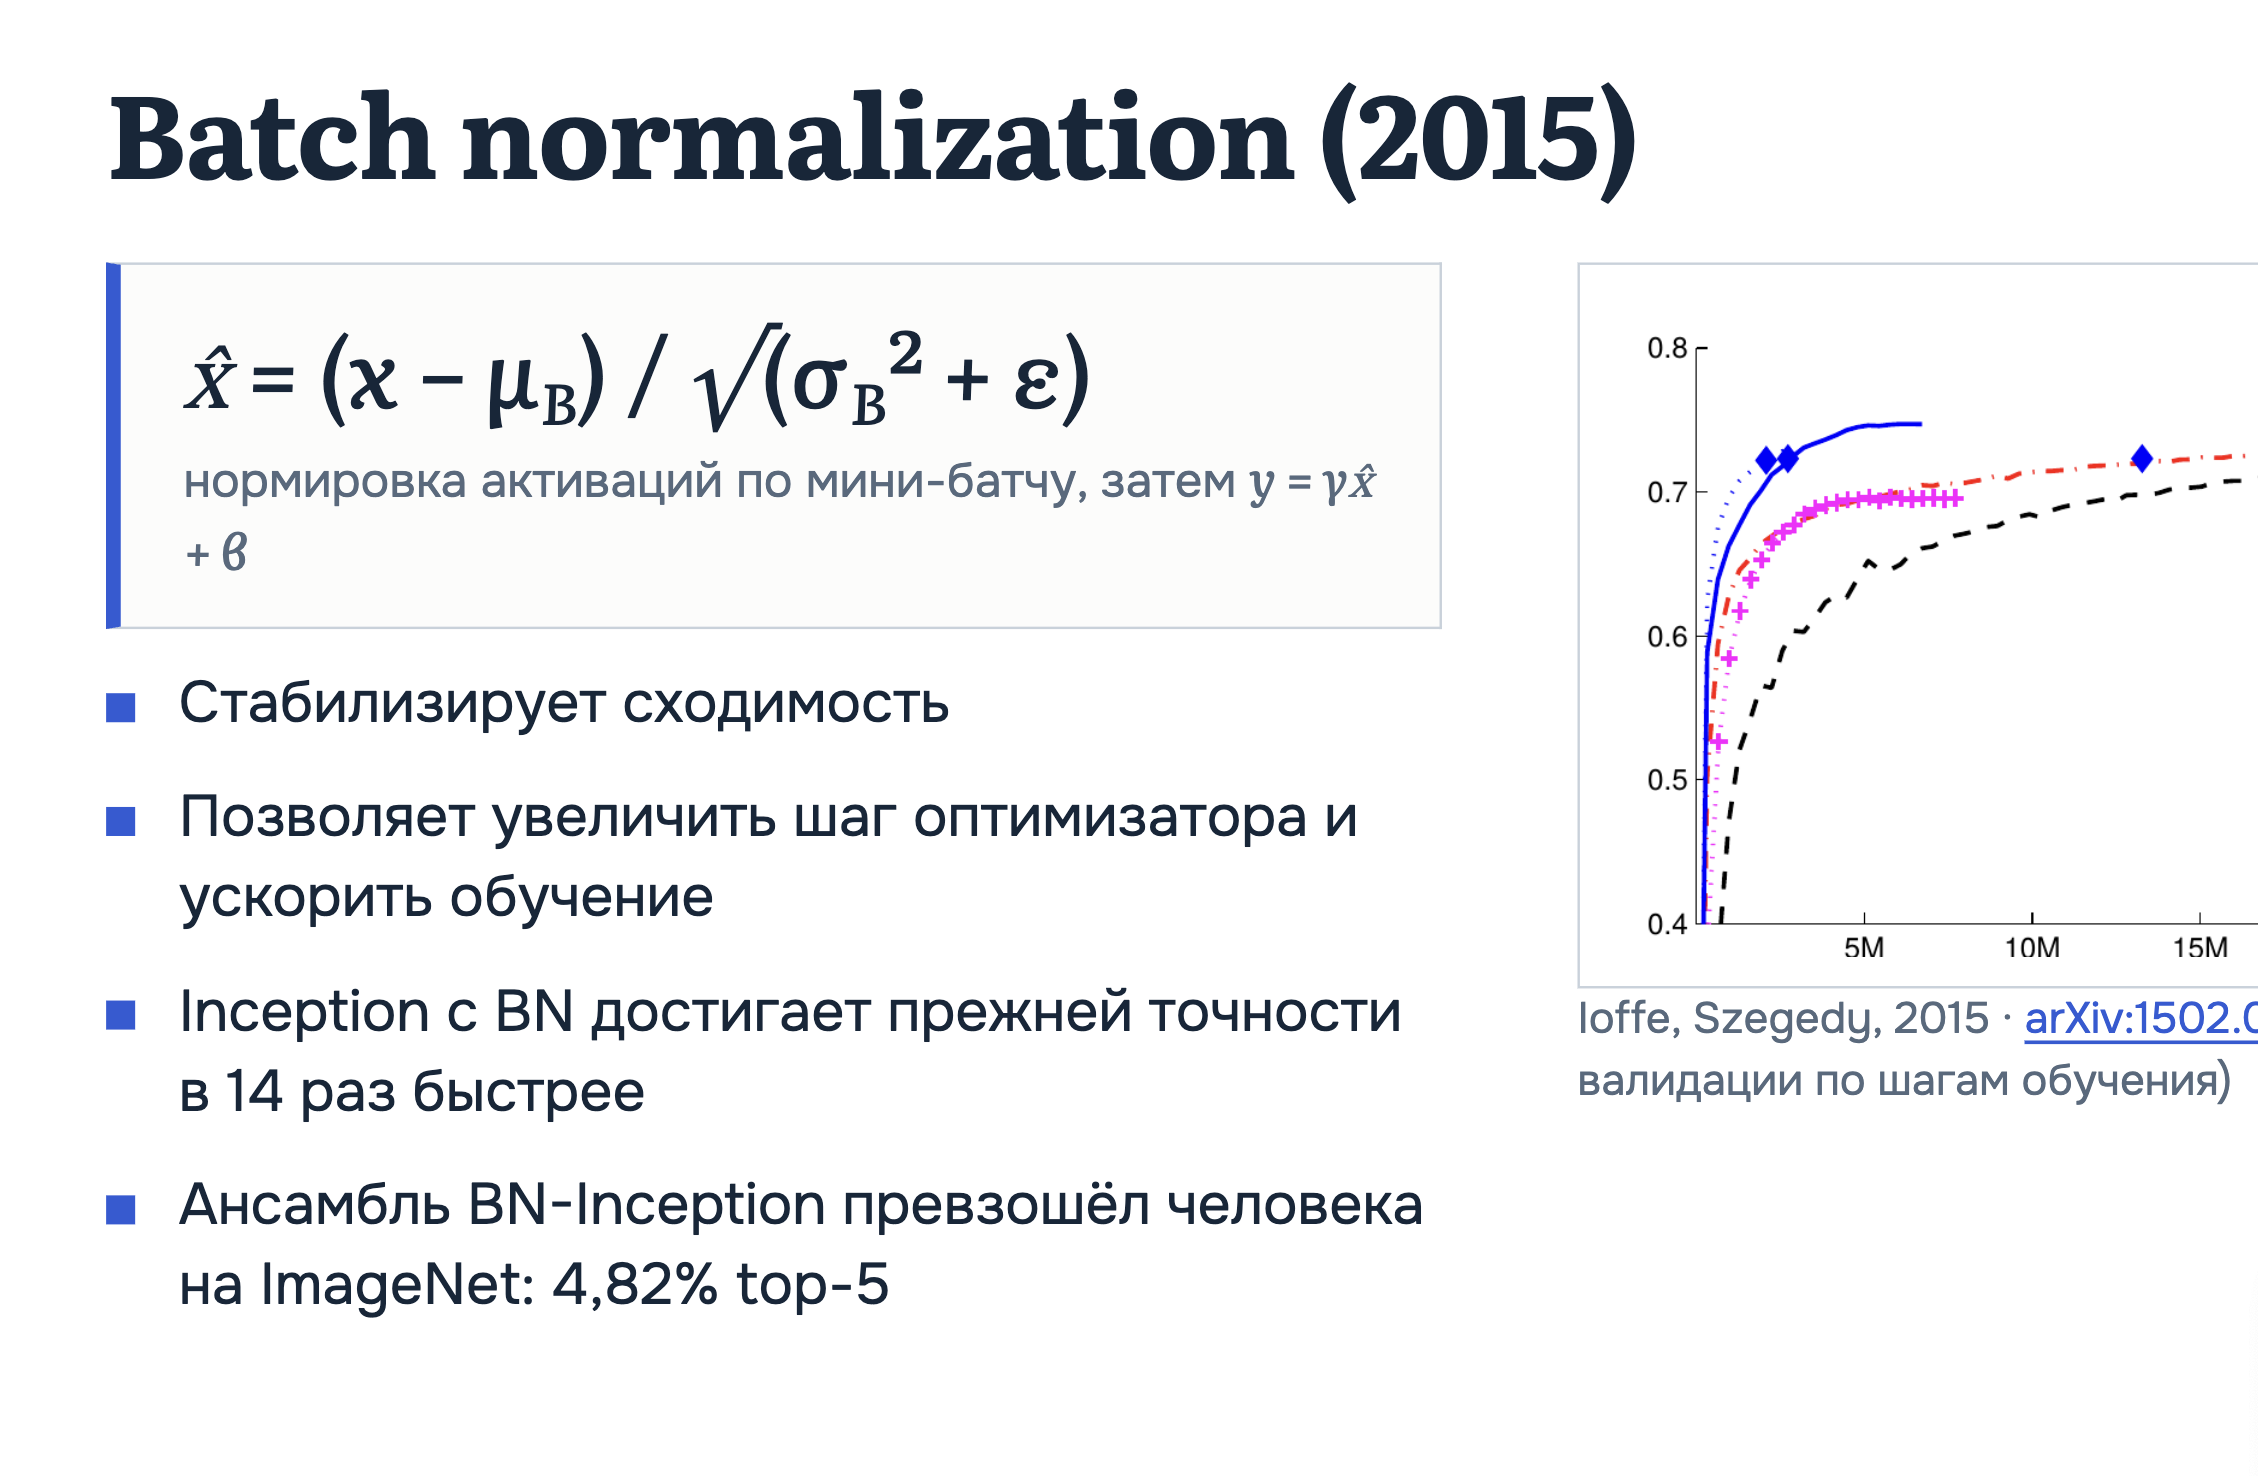

In [ ]:
def batch_norm_bchw(x, gamma, beta, eps=1e-5):
    """x: (B, C, H, W), gamma, beta: (C,) -> (B, C, H, W)"""
    mean = x.mean(axis=(0, 2, 3), keepdims=True)
    var = x.var(axis=(0, 2, 3), keepdims=True)
    x_hat = (x-mean) / np.sqrt(var+eps)
    result = gamma.reshape(1, -1, 1, 1) * x_hat + beta.reshape(1, -1, 1, 1)
    return result

In [ ]:
rng = np.random.default_rng(0)
B, C, H, W = 8, 5, 6, 6
x = rng.normal(loc=3.0, scale=2.0, size=(B, C, H, W))
gamma, beta = rng.normal(size=C), rng.normal(size=C)

bn = nn.BatchNorm2d(C).double()
bn.weight.data, bn.bias.data = torch.from_numpy(gamma), torch.from_numpy(beta)
bn.train()
ref = bn(torch.from_numpy(x)).detach().numpy()

out = batch_norm_bchw(x, gamma, beta)
assert np.allclose(out, ref, atol=1e-6), 'не совпало с nn.BatchNorm2d'
print('batch_norm_bchw ✓')
print('среднее по каналам  ≈ beta :', np.allclose(out.mean(axis=(0, 2, 3)), beta, atol=1e-6))

batch_norm_bchw ✓
среднее по каналам  ≈ beta : True


## Часть 2. Transfer learning на классификации

**Задача.** Датасет Oxford Flowers-102: 102 вида цветов, нам дадут всего **1020 обучающих картинок** (по 10 на класс) и 1020 для проверки. Сравним три способа:

| способ | что учим | с чего начинаем |
|---|---|---|
| from zero | всё | случайные веса |
| linear probing (LP) | только новую голову | backbone заморожен, веса ImageNet |
| fine-tuning (FT) | голову и backbone | веса ImageNet |


### 2.1 Данные

In [ ]:
MAX_IMAGES = None   # для отладки на CPU можно поставить, например, 200

tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.PILToTensor()])
train_ds = datasets.Flowers102('data', split='train', transform=tf, download=True)
val_ds   = datasets.Flowers102('data', split='val',   transform=tf, download=True)

def to_tensors(ds, limit=None):
    n = len(ds) if limit is None else min(limit, len(ds))
    xs, ys = zip(*[ds[i] for i in range(n)])
    return torch.stack(xs), torch.tensor(ys)

Xtr, Ytr = to_tensors(train_ds, MAX_IMAGES)
Xva, Yva = to_tensors(val_ds, MAX_IMAGES)
print(Xtr.shape, Xtr.dtype, '| классов:', len(set(Ytr.tolist())), '| val:', Xva.shape[0])

100%|██████████| 345M/345M [00:20<00:00, 17.0MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.45MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 37.5MB/s]


torch.Size([1020, 3, 224, 224]) torch.uint8 | классов: 102 | val: 1020


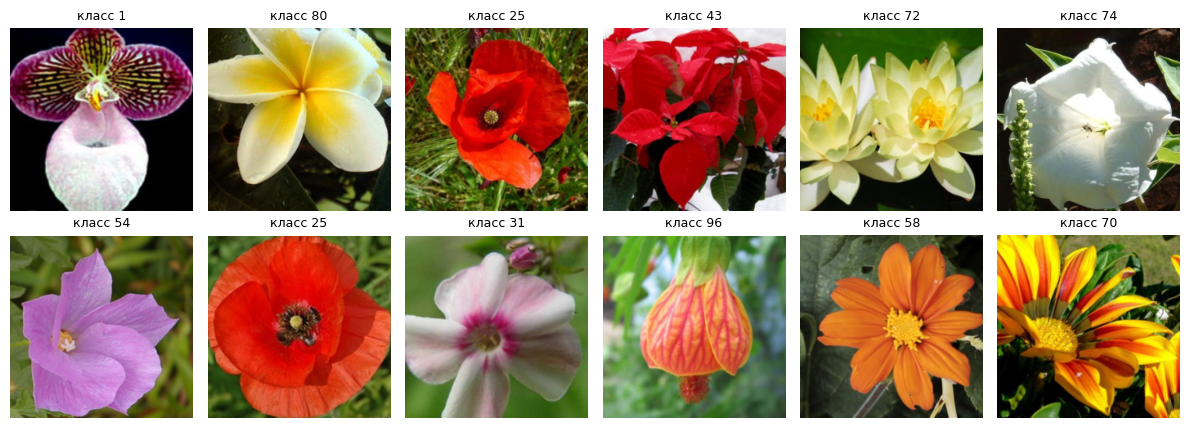

In [ ]:
fig, ax = plt.subplots(2, 6, figsize=(12, 4.4))
for a, i in zip(ax.ravel(), torch.randperm(len(Xtr))[:12]):
    a.imshow(Xtr[i].permute(1, 2, 0)); a.set_title(f'класс {Ytr[i].item()}', fontsize=9); a.axis('off')
plt.tight_layout(); plt.show()

### 2.2 Вспомогательный код (читать не обязательно, но можно)

In [ ]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1) * 255
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1) * 255

def prep(xb, train):
    xb = xb.to(device).float()
    if train:   # случайное отражение по горизонтали (слайд про аугментации)
        flip = torch.rand(xb.size(0), device=device) < 0.5
        xb = torch.where(flip.view(-1, 1, 1, 1), xb.flip(3), xb)
    return (xb - MEAN) / STD

@torch.no_grad()
def evaluate(model, X, Y, bs=128):
    model.eval(); correct = 0
    for i in range(0, len(X), bs):
        correct += (model(prep(X[i:i + bs], False)).argmax(1).cpu() == Y[i:i + bs]).sum().item()
    return correct / len(X)

def fit(model, optimizer, epochs, backbone_frozen=False, bs=64, name=''):
    hist = {'loss': [], 'val_acc': [], 'time': []}
    t0 = time.time()
    for ep in range(epochs):
        if backbone_frozen:
            model.eval()          # BatchNorm в backbone не обновляет статистики
        else:
            model.train()
        perm, total = torch.randperm(len(Xtr)), 0.0
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]
            xb, yb = prep(Xtr[idx], True), Ytr[idx].to(device)
            loss = F.cross_entropy(model(xb), yb)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item() * len(idx)
        acc = evaluate(model, Xva, Yva)
        hist['loss'].append(total / len(Xtr)); hist['val_acc'].append(acc); hist['time'].append(time.time() - t0)
        print(f'{name:8s} эпоха {ep + 1}/{epochs}  loss {hist["loss"][-1]:.3f}  val acc {acc:.3f}  ({hist["time"][-1]:.0f} с)')
    return hist

### 2.3 Собираем модели

Возьмём ResNet-18. Её голова, слой `fc`, выдаёт 1000 классов ImageNet; у нас 102, поэтому **заменяем голову** на новый `nn.Linear(512, 102)`. Остальное зависит от режима. Заполните функцию.

In [ ]:
def make_model(mode):
    """mode: 'scratch' | 'lp' | 'ft'  ->  (model, optimizer)"""
    weights = models.ResNet18_Weights.DEFAULT if mode in ('lp', 'ft') else None
    model = models.resnet18(weights=weights)
    model.fc = nn.Linear(512, 102)

    # новая голова

    # TODO:
    #  scratch -> Adam(lr=1e-3) по всем параметрам
    #  lp      -> заморозить всё, кроме model.fc (requires_grad=False), Adam(lr=1e-3) только по fc
    #  ft      -> учим всё, но у backbone lr=1e-4, а у головы lr=1e-3 (две группы параметров)

    if mode == 'scratch':
      optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    if mode == 'lp':
      for p in model.parameters():
        p.requires_grad = False
      for p in model.fc.parameters():
        p.requires_grad = True
      optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
    if mode == 'ft':
      head_ids = {id(p) for p in model.fc.parameters()}
      body = [p for p in model.parameters() if id(p) not in head_ids]
      optimizer = torch.optim.Adam([
          {'params': body, 'lr': 1e-4},
          {'params': model.fc.parameters(), 'lr': 1e-3},
      ])

    return model.to(device), optimizer

In [ ]:
def trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

m_lp, o_lp = make_model('lp')
m_ft, o_ft = make_model('ft')
m_sc, o_sc = make_model('scratch')
assert trainable(m_lp) == 512 * 102 + 102, 'в LP должна учиться только голова'
assert trainable(m_ft) == trainable(m_sc) > 11_000_000, 'в FT и scratch учится вся сеть'
assert len(o_ft.param_groups) == 2, 'в FT должно быть две группы параметров'
print('учится параметров: LP', trainable(m_lp), '| FT', trainable(m_ft), '| scratch', trainable(m_sc), ' ✓')

учится параметров: LP 52326 | FT 11228838 | scratch 11228838  ✓


### 2.4 Запускаем три эксперимента

In [ ]:
EPOCHS = 5
hist = {}
hist['lp']      = fit(m_lp, o_lp, EPOCHS, backbone_frozen=True, name='LP')
hist['ft']      = fit(m_ft, o_ft, EPOCHS, name='FT')
hist['scratch'] = fit(m_sc, o_sc, EPOCHS, name='scratch')

LP       эпоха 1/5  loss 4.613  val acc 0.160  (2 с)
LP       эпоха 2/5  loss 3.712  val acc 0.436  (5 с)
LP       эпоха 3/5  loss 3.019  val acc 0.590  (7 с)
LP       эпоха 4/5  loss 2.479  val acc 0.685  (10 с)
LP       эпоха 5/5  loss 2.019  val acc 0.734  (12 с)
FT       эпоха 1/5  loss 4.286  val acc 0.513  (5 с)
FT       эпоха 2/5  loss 2.089  val acc 0.762  (10 с)
FT       эпоха 3/5  loss 0.906  val acc 0.858  (15 с)
FT       эпоха 4/5  loss 0.383  val acc 0.887  (19 с)
FT       эпоха 5/5  loss 0.183  val acc 0.903  (24 с)
scratch  эпоха 1/5  loss 4.497  val acc 0.044  (4 с)
scratch  эпоха 2/5  loss 3.612  val acc 0.061  (9 с)
scratch  эпоха 3/5  loss 3.244  val acc 0.127  (13 с)
scratch  эпоха 4/5  loss 2.899  val acc 0.209  (17 с)
scratch  эпоха 5/5  loss 2.685  val acc 0.207  (21 с)


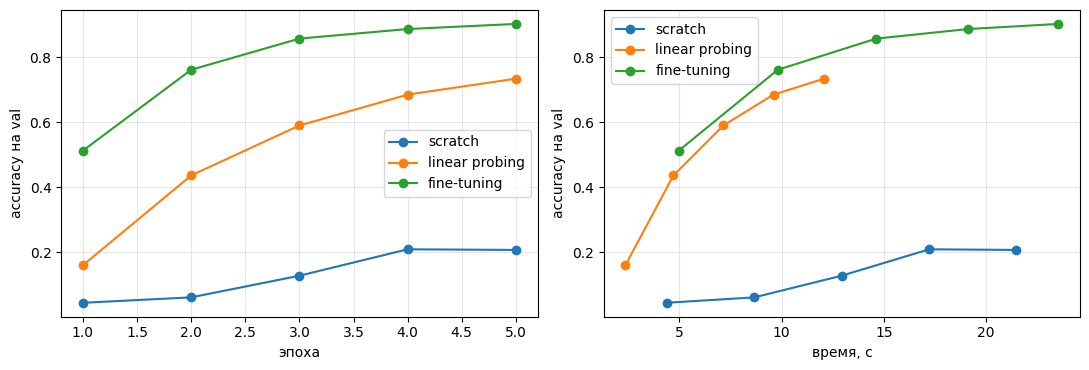

способ            acc    время   учится параметров
scratch         0.207      21с          11,228,838
lp              0.734      12с              52,326
ft              0.903      24с          11,228,838


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, lab in [('scratch', 'scratch'), ('lp', 'linear probing'), ('ft', 'fine-tuning')]:
    ax[0].plot(range(1, EPOCHS + 1), hist[k]['val_acc'], marker='o', label=lab)
    ax[1].plot(hist[k]['time'], hist[k]['val_acc'], marker='o', label=lab)
ax[0].set_xlabel('эпоха'); ax[1].set_xlabel('время, с')
for a in ax: a.set_ylabel('accuracy на val'); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

print(f"{'способ':14s}{'acc':>7s}{'время':>9s}{'учится параметров':>20s}")
for k, m in [('scratch', m_sc), ('lp', m_lp), ('ft', m_ft)]:
    print(f"{k:14s}{hist[k]['val_acc'][-1]:7.3f}{hist[k]['time'][-1]:8.0f}с{trainable(m):20,d}")

### 2.5 Что выучил backbone (наглядно)

Посмотрим, что лежит внутри. Фильтры первого слоя: слева предобученные на ImageNet, справа случайные.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 214MB/s]


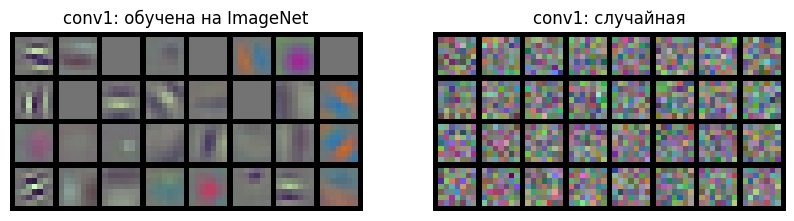

In [ ]:
def show_filters(w, title, ax):
    w = (w - w.min()) / (w.max() - w.min())
    grid = torchvision.utils.make_grid(w[:32], nrow=8, padding=1)
    ax.imshow(grid.permute(1, 2, 0)); ax.set_title(title); ax.axis('off')

pre = models.resnet18(weights=models.ResNet18_Weights.DEFAULT).conv1.weight.detach()
rnd = models.resnet18().conv1.weight.detach()
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
show_filters(pre, 'conv1: обучена на ImageNet', ax[0]); show_filters(rnd, 'conv1: случайная', ax[1])
plt.show()

Теперь карты признаков одной картинки на разной глубине: после первой стадии (`layer1`) и после последней (`layer4`). Мы берём предобученную сеть и перехватываем выходы хуками.

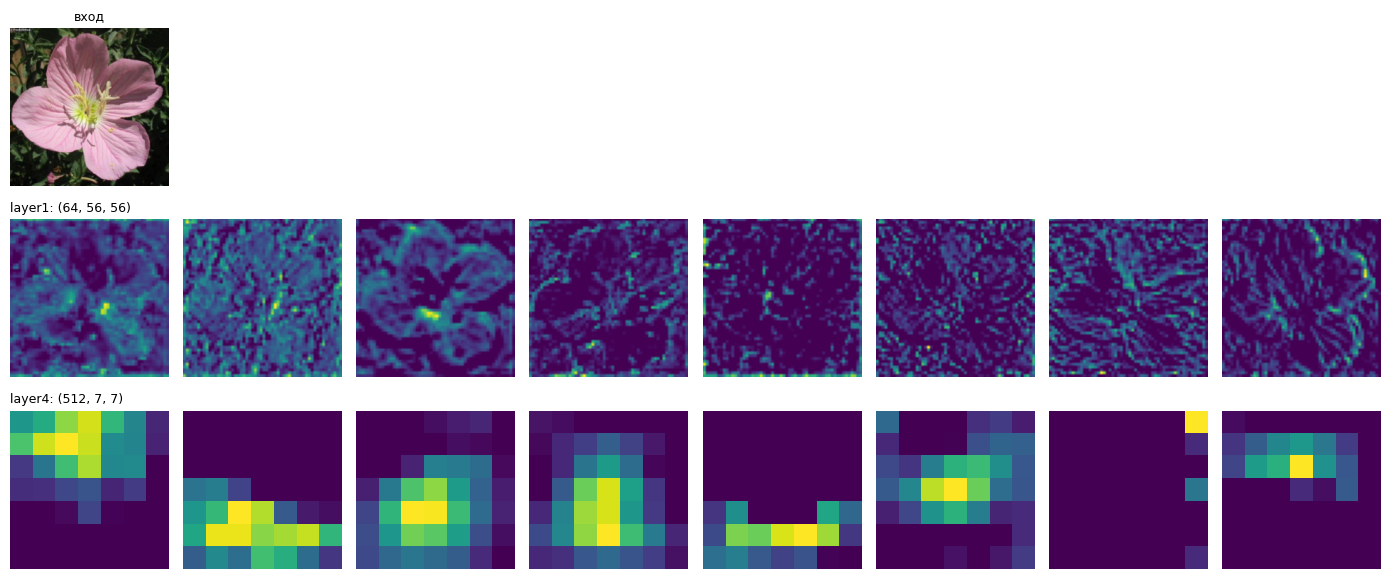

In [ ]:
probe = models.resnet18(weights=models.ResNet18_Weights.DEFAULT).eval().to(device)
feats = {}
probe.layer1.register_forward_hook(lambda m, i, o: feats.__setitem__('layer1', o.detach().cpu()))
probe.layer4.register_forward_hook(lambda m, i, o: feats.__setitem__('layer4', o.detach().cpu()))
with torch.no_grad():
    probe(prep(Xva[:1], False))

fig, ax = plt.subplots(3, 8, figsize=(14, 6))
for a in ax[0]: a.axis('off')
ax[0, 0].imshow(Xva[0].permute(1, 2, 0)); ax[0, 0].set_title('вход', fontsize=9)
for row, name in [(1, 'layer1'), (2, 'layer4')]:
    f = feats[name][0]
    for j in range(8):
        ax[row, j].imshow(f[j * (f.shape[0] // 8)], cmap='viridis'); ax[row, j].axis('off')
    ax[row, 0].set_title(f'{name}: {tuple(f.shape)}', fontsize=9, loc='left')
plt.tight_layout(); plt.show()

In [ ]:
#написать даталоаудер и саму модельку на след семинар

## Часть 3.  Backbone без головы

Снимем с дообученной сети голову (`avgpool` и `fc`) и посмотрим, что остаётся на выходе

In [ ]:
backbone = nn.Sequential(*list(m_ft.children())[:-2]).eval()   # без avgpool и fc
x = prep(Xva[:2], False)
with torch.no_grad():
    maps = backbone(x)
print('выход backbone:', tuple(maps.shape), '  (B, каналов, H, W)')

big = torch.randn(1, 3, 320, 480, device=device)
with torch.no_grad():
    print('для картинки 320×480:', tuple(backbone(big).shape))

выход backbone: (2, 512, 7, 7)   (B, каналов, H, W)
для картинки 320×480: (1, 512, 10, 15)


Голова классификации = **GAP + линейный слой**. Реализуйте её сами поверх карт признаков и убедитесь, что получаете те же логиты, что и у целой модели.

In [ ]:
def classification_head(maps, fc):
    """maps: (B, 512, H, W) -> логиты (B, 102)"""
    # TODO: усреднить по H и W, затем применить fc
    return fc(maps.mean(dim=(2,3)))


In [ ]:
with torch.no_grad():
    mine = classification_head(maps, m_ft.fc)
    full = m_ft.eval()(x)
assert torch.allclose(mine, full, atol=1e-5), 'логиты не совпали с моделью'
print('голова = GAP + Linear ✓')

with torch.no_grad():
    print('логиты для картинки 320×480:', tuple(classification_head(backbone(big), m_ft.fc).shape))

голова = GAP + Linear ✓
логиты для картинки 320×480: (1, 102)


## Часть 4. Аугментации

Данных мало: 10 картинок на класс. Сеть с 11 млн параметров легко **запоминает** обучающую выборку, и качество на val от этого не растёт. Аугментации искусственно расширяют датасет: к каждой картинке на лету применяется случайное преобразование, которое **не меняет класс** (цветок после сдвига или отражения остаётся тем же цветком). Сеть на каждой эпохе видит чуть другие картинки, и запомнить их дословно становится сложнее. Это регуляризация через данные.

Правила:
- аугментируем **только train**; на val и test подаём картинку как есть (иначе метрика станет случайной);
- преобразование должно сохранять метку: для цветов отражение по горизонтали подходит, а для цифр `6` и `9` уже нет;
- аугментация применяется **до нормализации** (на uint8-картинке), нормализация идёт последней.

### 4.1 Random crop с паддингом

Классическая аугментация для небольших изображений: дополнить картинку нулями на `pad` пикселей со всех сторон и вырезать случайное окно исходного размера `H×W`. Фактически это случайный сдвиг объекта. **Сдвиг должен быть свой для каждой картинки в батче.**

In [ ]:
def random_crop(x, pad, rng):
    """x: (B, C, H, W) -> (B, C, H, W). Паддинг нулями на pad пикселей, у каждой картинки свой случайный сдвиг."""
    pass

In [ ]:
rng = np.random.default_rng(0)
B, C, H, W, pad = 16, 3, 8, 8, 2
x = rng.normal(size=(B, C, H, W))

out = random_crop(x, pad, np.random.default_rng(1))
assert out.shape == x.shape, 'форма должна сохраняться'
assert np.allclose(random_crop(x, 0, np.random.default_rng(1)), x), 'при pad=0 картинка не меняется'

padded = np.pad(x, ((0, 0), (0, 0), (pad, pad), (pad, pad)))
offsets = []
for b in range(B):
    found = [(i, j) for i in range(2 * pad + 1) for j in range(2 * pad + 1)
             if np.allclose(out[b], padded[b, :, i:i + H, j:j + W])]
    assert found, f'картинка {b}: результат не является окном дополненной картинки'
    offsets.append(found[0])
assert len(set(offsets)) > 1, 'у разных картинок должны быть разные сдвиги'
print('random_crop ✓')

### 4.2 Аугментации из torchvision

Реализовывать всё руками не нужно: в `torchvision.transforms.v2` есть готовые преобразования, которые работают и с тензорами. Соберите пайплайн **`aug_strong`** из трёх шагов:

1. `RandomResizedCrop(224, scale=(0.4, 1.0))`: случайный участок площадью 40–100% картинки, растянутый до 224×224 (меняет масштаб и положение);
2. `RandomHorizontalFlip()`;
3. `ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.03)`: небольшие изменения цвета (освещение, камера).

In [ ]:
from torchvision.transforms import v2

aug_flip = v2.RandomHorizontalFlip(p=0.5)
crop = v2.RandomResizedCrop(224, scale=(0.4, 1.0))
jitter = v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.03)

aug_strong = v2.Compose([aug_flip, crop, jitter])

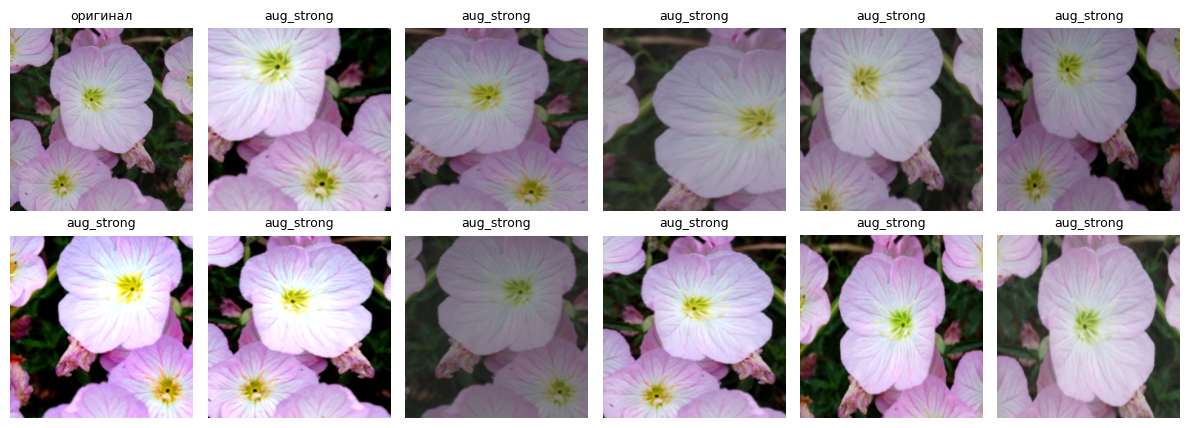

In [ ]:
out = aug_strong(Xtr[0])
assert out.shape == (3, 224, 224) and out.dtype == torch.uint8, 'ожидается uint8-картинка 3×224×224'

fig, ax = plt.subplots(2, 6, figsize=(12, 4.4))
ax[0, 0].imshow(Xtr[0].permute(1, 2, 0)); ax[0, 0].set_title('оригинал', fontsize=9)
for a in ax.ravel()[1:]:
    a.imshow(aug_strong(Xtr[0]).permute(1, 2, 0))
    a.set_title('aug_strong', fontsize=9)
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

### 4.3 Эксперимент: помогают ли аугментации?

Дообучаем (fine-tuning) одну и ту же модель трижды, меняя только аугментацию: без неё, только отражение и сильная. Кроме точности на val, следим за **разрывом** `train acc − val acc`: чем он больше, тем сильнее переобучение.

Аугментация применяется к каждой картинке батча отдельно (у каждой свои случайные параметры), поэтому цикл по батчу немного медленнее обычного.

In [ ]:
def fit_aug(model, optimizer, epochs, aug=None, bs=64, name=''):
    hist = {'train_acc': [], 'val_acc': []}
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]
            xb = Xtr[idx]
            if aug is not None:                              # на каждую картинку свои случайные параметры
                xb = torch.stack([aug(img) for img in xb])
            loss = F.cross_entropy(model(prep(xb, False)), Ytr[idx].to(device))
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        tr, va = evaluate(model, Xtr, Ytr), evaluate(model, Xva, Yva)   # обе оценки без аугментации
        hist['train_acc'].append(tr); hist['val_acc'].append(va)
        print(f'{name:8s} эпоха {ep + 1}/{epochs}  train acc {tr:.3f}  val acc {va:.3f}')
    return hist

AUG_EPOCHS = 8
hist_aug = {}
for key, aug in [('none', None), ('flip', aug_flip), ('strong', aug_strong)]:
    m, o = make_model('ft')
    hist_aug[key] = fit_aug(m, o, AUG_EPOCHS, aug=aug, name=key)

none     эпоха 1/8  train acc 0.820  val acc 0.493
none     эпоха 2/8  train acc 0.989  val acc 0.769
none     эпоха 3/8  train acc 1.000  val acc 0.846
none     эпоха 4/8  train acc 1.000  val acc 0.861
none     эпоха 5/8  train acc 1.000  val acc 0.883
none     эпоха 6/8  train acc 1.000  val acc 0.886
none     эпоха 7/8  train acc 1.000  val acc 0.891
none     эпоха 8/8  train acc 1.000  val acc 0.892
flip     эпоха 1/8  train acc 0.705  val acc 0.453
flip     эпоха 2/8  train acc 0.961  val acc 0.763
flip     эпоха 3/8  train acc 0.993  val acc 0.833
flip     эпоха 4/8  train acc 0.998  val acc 0.877
flip     эпоха 5/8  train acc 0.999  val acc 0.894
flip     эпоха 6/8  train acc 0.999  val acc 0.896
flip     эпоха 7/8  train acc 0.999  val acc 0.900
flip     эпоха 8/8  train acc 1.000  val acc 0.904
strong   эпоха 1/8  train acc 0.508  val acc 0.354
strong   эпоха 2/8  train acc 0.836  val acc 0.668
strong   эпоха 3/8  train acc 0.953  val acc 0.783
strong   эпоха 4/8  train acc 0

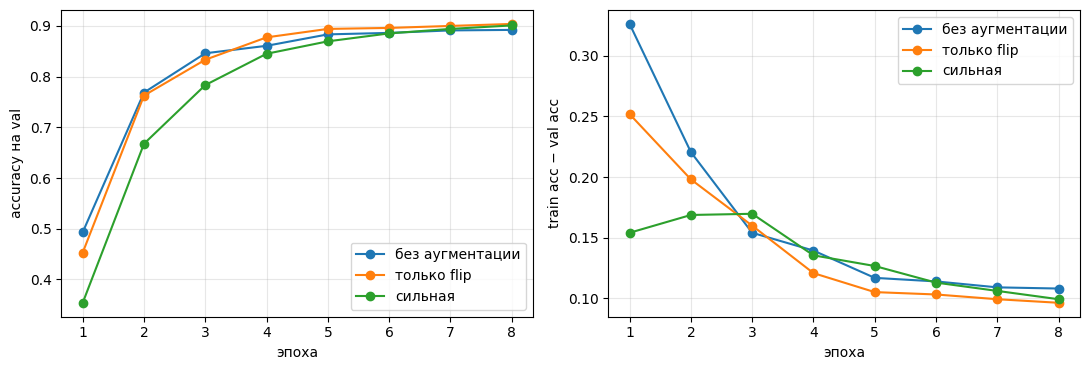

аугментация     val acc   разрыв
none              0.892    0.108
flip              0.904    0.096
strong            0.901    0.099


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ep = range(1, AUG_EPOCHS + 1)
for k, lab in [('none', 'без аугментации'), ('flip', 'только flip'), ('strong', 'сильная')]:
    h = hist_aug[k]
    ax[0].plot(ep, h['val_acc'], marker='o', label=lab)
    ax[1].plot(ep, np.array(h['train_acc']) - np.array(h['val_acc']), marker='o', label=lab)
ax[0].set_ylabel('accuracy на val'); ax[1].set_ylabel('train acc − val acc')
for a in ax: a.set_xlabel('эпоха'); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

print(f"{'аугментация':14s}{'val acc':>9s}{'разрыв':>9s}")
for k in ['none', 'flip', 'strong']:
    h = hist_aug[k]
    print(f"{k:14s}{h['val_acc'][-1]:9.3f}{h['train_acc'][-1] - h['val_acc'][-1]:9.3f}")